# Klasifikasi fraud
 ## Tujuan demo
 Jalankan sel dari atas ke bawah. Penjelasan, tabel, dan grafik memakai keluaran run baru di `.cache/demo-notebook/klasifikasi/`.
 Kode eksperimen utama berada di `klasifikasi.py` dan dipanggil langsung oleh notebook ini.

 Sebelum demo, gunakan Python 3.12 dan pasang dependensi dari root repo dengan
 `python -m pip install -r kode/requirements-notebook.txt`.
 Simpan data rilis dosen di `data_uts_ml/`. Notebook ini dapat dibuka melalui JupyterLab atau VS Code.
 Untuk Colab, unggah salinan repo lengkap dan data terlebih dahulu, lalu buka notebook ini dari folder repo.

## 1. Persiapan lingkungan

In [1]:
TASK = 'klasifikasi'
INPUTS = ['klasifikasi_train.csv.gz', 'klasifikasi_test.csv.gz']
from pathlib import Path
import importlib.util
import json
import os
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
ROOT = current if (current / "kode").is_dir() else current.parent
assert (ROOT / "kode" / (TASK + ".py")).is_file(), "Buka notebook dari root repo atau folder kode/."
DATA = Path(os.environ.get("UTS_DATA_DIR", ROOT / "data_uts_ml"))
OUTPUT = ROOT / ".cache" / "demo-notebook" / TASK
OUTPUT.mkdir(parents=True, exist_ok=True)

spec = importlib.util.spec_from_file_location("eksperimen_" + TASK, ROOT / "kode" / (TASK + ".py"))
experiment = importlib.util.module_from_spec(spec)
spec.loader.exec_module(experiment)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True})

## 2. Data dan pertanyaan
Satu baris data merepresentasikan satu transaksi. Tampilkan lima contoh untuk membaca kolom yang dipakai.

In [2]:
sample = pd.read_csv(DATA / INPUTS[0], nrows=5)
display(sample[['id_transaksi', 'waktu', 'nominal', 'perangkat_baru', 'is_fraud']])

,id_transaksi,waktu,nominal,perangkat_baru,is_fraud
0,T464739637,2025-07-19 19:30:41,26600.0,0,0
1,T555813708,2025-08-18 20:49:21,179300.0,0,0
2,T998564616,2025-02-25 03:29:04,58800.0,0,0
3,T221231710,2025-07-04 10:09:24,147400.0,0,0
4,T253111101,2025-08-28 23:09:19,305400.0,0,0


## 3. Metode dan asumsi
 Skor dipakai saat transaksi terjadi. Flag review manual dikeluarkan dari model akhir.
 Riwayat hanya memakai kejadian dengan waktu lebih awal. Jeda label 14 hari adalah asumsi.
 Kami membandingkan tanpa bobot, bobot positif, dan undersampling pada Mei-Juni.
 Fit, kalibrasi sigmoid, pemilihan ambang biaya, serta evaluasi memakai cohort terpisah.

## 4. Jalankan ulang eksperimen
Sel ini menghitung riwayat, memilih model, mengalibrasi probabilitas, dan mengekspor prediksi.

In [3]:
missing = [name for name in INPUTS if not (DATA / name).is_file()]
assert not missing, "Masukkan data dosen ke data_uts_ml/. Berkas belum ada: " + ", ".join(missing)
start = time.perf_counter()
subprocess.run(
    [sys.executable, str(ROOT / "kode" / (TASK + ".py")), "--data", str(DATA), "--output", str(OUTPUT)],
    check=True,
)
print(f"Eksperimen selesai dalam {time.perf_counter() - start:.1f} detik.")
metrics = json.loads((OUTPUT / "hasil" / TASK / "metrics.json").read_text(encoding="utf-8"))

Eksperimen selesai dalam 48.2 detik.


## 5. Dari mana Rp72.651.400 berasal?

In [4]:
early = metrics["august"]["early_mature_14d"]
selected = early["selected_cost_rule"]
calculated_cost = selected["alerts"] * experiment.REVIEW_COST + selected["missed_nominal"]
assert calculated_cost == selected["total_cost"]
print(f"{selected['alerts']} review × Rp{experiment.REVIEW_COST:,} + Rp{selected['missed_nominal']:,.0f}")
print(f"Total biaya simulasi awal Agustus: Rp{calculated_cost:,.0f}")
display(pd.DataFrame([selected])[["true_positive", "false_positive", "false_negative", "precision", "recall"]])

464 review × Rp25,000 + Rp61,051,400
Total biaya simulasi awal Agustus: Rp72,651,400


,true_positive,false_positive,false_negative,precision,recall
0,127,337,65,0.273707,0.661458


## 6. Bandingkan kebijakan review

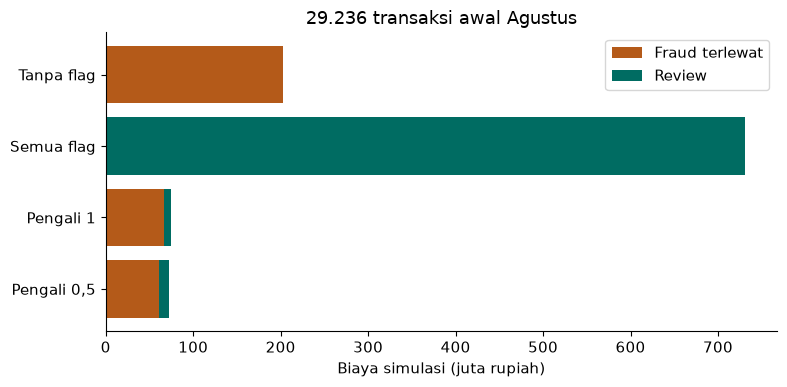

In [5]:
keys = ["baseline_none", "baseline_all", "theoretical_cost_rule", "selected_cost_rule"]
labels = ["Tanpa flag", "Semua flag", "Pengali 1", "Pengali 0,5"]
missed = [early[key]["missed_nominal"] / 1e6 for key in keys]
review = [early[key]["review_cost"] / 1e6 for key in keys]
fig, ax = plt.subplots()
ax.barh(labels, missed, label="Fraud terlewat", color="#B45A19")
ax.barh(labels, review, left=missed, label="Review", color="#006C62")
ax.invert_yaxis()
ax.set(xlabel="Biaya simulasi (juta rupiah)", title="29.236 transaksi awal Agustus")
ax.legend()
plt.tight_layout()
plt.show()

Ambang keputusan terpilih Rp12.500, sedangkan biaya tetap Rp25.000 untuk setiap review. Label test tersembunyi, sehingga biaya total resmi belum dapat dihitung.

## 7. Periksa keluaran resmi

In [6]:
predictions = pd.read_csv(OUTPUT / "prediksi_klasifikasi.csv")
assert predictions["id_transaksi"].is_unique and predictions["prob"].between(0, 1).all()
assert predictions["tandai"].isin([0, 1]).all()
print(f"{len(predictions):,} transaksi; {predictions['tandai'].sum():,} flag.")
display(predictions.head())

106,674 transaksi; 2,918 flag.


,id_transaksi,prob,tandai
0,T502861791,0.006667,0
1,T980390558,0.001714,0
2,T657838379,0.001282,0
3,T985886276,0.003773,0
4,T852019235,0.008496,0


## Latihan menjawab
 Sebutkan tujuan eksperimen, satu keputusan metode, angka yang baru dihitung, dan batas kesimpulannya.
 Buka `../laporan.pdf` untuk pembahasan semua subsoal dan `../hasil/` untuk bukti tersimpan.